# Taller de Aprendizaje No Supervisado
## Parte 1: Dataset de Setas (variables categóricas)

### Mushroom Dataset

Podéis obtener el conjunto de datos en el siguiente enlace:

[Mushroom Dataset](https://www.kaggle.com/uciml/mushroom-classification)

Como podréis comprobar, hay **muchas variables, todas categóricas**, por lo que las exploraciones con *scatterplot* no nos serán útiles como en otros casos.

La variable a predecir es `class` (`e` = comestible / *edible*, `p` = venenosa / *poisonous*) y es **binaria**.

> En este taller usaremos las etiquetas **solo para validar** lo que descubre el clustering. La idea del aprendizaje no supervisado es encontrar estructura *sin* mirar la etiqueta.

### Algoritmos que cubriremos

**Reducción de dimensionalidad:** PCA (lineal) y t-SNE (no lineal).

**Clustering:** K-Means, Clustering Jerárquico (Aglomerativo), Gaussian Mixture Models (GMM) y DBSCAN.

**Evaluación:** método del codo, *silhouette*, Davies-Bouldin, Calinski-Harabasz y (como tenemos etiqueta) Adjusted Rand Index y NMI.

**Detección de anomalías:** Isolation Forest.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook, justo debajo de la celda que los crea.
import warnings
warnings.filterwarnings("ignore")  # oculta avisos (FutureWarning, etc.) para que la salida quede limpia en clase

# Tablas y cálculo numérico
import pandas as pd      # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np       # arrays y operaciones matemáticas rápidas
# Gráficos
import seaborn as sns            # gráficos estadísticos bonitos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos (títulos, ejes, plt.show())
# Preparación de datos y reducción de dimensiones
from sklearn.model_selection import train_test_split  # separa datos en entrenamiento y examen
from sklearn.decomposition import PCA                 # reducción de dimensiones lineal
# Algoritmos de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.manifold import TSNE                     # reducción de dimensiones no lineal (solo para visualizar)
from sklearn.mixture import GaussianMixture          # GMM: clusters como "nubes" probabilísticas
# Modelos supervisado y de anomalías
from sklearn.ensemble import RandomForestClassifier, IsolationForest
# Métricas para evaluar los clusters (3 internas + 2 que usan la etiqueta: ARI y NMI)
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
# Para dibujar el dendrograma
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')  # estilo visual de todos los gráficos: fondo blanco con rejilla
RANDOM_STATE = 42 

### Leer conjunto de datos y primer vistazo

In [2]:
# Leer el csv (esta en 'data/mushrooms.csv') y sacar por pantalla las cinco primeras filas.
df = pd.read_csv("data/mushrooms.csv")  # cargamos el dataset en un DataFrame
df.head()                               # vistazo rápido a las 5 primeras filas


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Exploración de datos

In [3]:
# Descripcion del conjunto de datos, estandar.
print("Filas y columnas:", df.shape)  # tamaño del dataset (filas, columnas)
print(df["class"].value_counts(normalize=True))     # proporción de cada clase (e / p)
df.describe()                                       # count, unique, top y freq de cada variable

Filas y columnas: (8124, 23)
class
e    0.517971
p    0.482029
Name: proportion, dtype: float64


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


> **📝 Observación:** El dataset tiene 8124 filas y 23 columnas, todas categóricas.
> - `veil-type` tiene un único valor → no aporta información y la eliminaremos.
> - La variable `class` está bastante equilibrada: **51,8 %** comestibles (`e`) y **48,2 %** venenosas (`p`).
>   Esto es importante porque no hay desbalance que distorsione la validación posterior (ARI/NMI).

In [4]:
# Informacion sobre el tipo de datos de cada feature.
df.info()   # tipo de dato y número de valores no nulos de cada columna

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

> **📝 Observación:** Todas las variables son de tipo `object` (categóricas) y no aparecen nulos.
> Sin embargo, hay que comprobar si existen valores desconocidos codificados de otra forma (p. ej. `'?'`).

#### Calcular el número de nulos de cada feature

In [5]:
# Igual que otras veces, una linea: contar los nulos por variable.
df.isnull().sum()  # contamos los nulos de cada columna

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

#### Buscar valores extraños. Para ello, ver los valores únicos en cada feature

In [6]:
# Obtener un nuevo dataframe: en una columna las features (feature)
# y en la otra el numero de valores unicos asociados (n_values).
n_values = pd.DataFrame({
    "feature": df.columns,                                    # nombre de la variable
    "n_values": df.nunique().values,                          # nº de valores distintos
    "valores": [sorted(df[c].unique()) for c in df.columns]   # (extra) cuáles son → aquí se ve el '?'
}).sort_values("n_values")                                    # de menor a mayor
n_values

,feature,n_values,valores
16,veil-type,1,[p]
0,class,2,"[e, p]"
4,bruises,2,"[f, t]"
6,gill-attachment,2,"[a, f]"
7,gill-spacing,2,"[c, w]"
8,gill-size,2,"[b, n]"
10,stalk-shape,2,"[e, t]"
18,ring-number,3,"[n, o, t]"
2,cap-surface,4,"[f, g, s, y]"
17,veil-color,4,"[n, o, w, y]"


In [7]:
# Buscamos el valor '?' (nulo encubierto) en cada columna
(df == "?").sum().loc[lambda s: s > 0]   # solo columnas que contienen '?'

stalk-root    2480
dtype: int64

Observad dos cosas:
- `veil-type` tiene **un único valor** → no aporta información.
- `stalk-root` contiene el valor `'?'`, que en realidad es un **valor desconocido (nulo encubierto)**.

#### Tratar aquellos valores que entendamos que sean nulos

**¿Qué hacemos con los 2480 `'?'` de `stalk-root`?**

| Opción | Consecuencia |
|---|---|
| A) Eliminar las filas | Perdemos 2480 filas (≈ 30 % de los datos) y la información de las otras 21 variables ❌ |
| B) Imputar con la moda | `'?'` se sustituye por el valor más frecuente; conserva todas las filas, pero distorsiona la distribución |
| C) Dejar `'?'` como categoría | "Desconocido" pasa a ser un valor más; no inventa información |

**Decisión:** imputamos con la **moda** (opción B), como indica el enunciado. Usamos la moda y no la media porque la variable es **categórica**.

In [8]:
df["stalk-root"].value_counts()

stalk-root
b    3776
?    2480
e    1120
c     556
r     192
Name: count, dtype: int64

In [9]:
# Imputaciones. Podeis quitar esos puntos (fila entera), imputar con la moda
# o dejar ese valor como una posibilidad mas. Aqui imputamos '?' con la moda.
df["stalk-root"] = df["stalk-root"].replace("?", np.nan)   # '?' → nulo real (NaN)
moda = df["stalk-root"].mode()[0]                          # valor más frecuente (sin contar NaN)
print("Moda de stalk-root:", moda)
df["stalk-root"] = df["stalk-root"].fillna(moda)           # imputamos con la moda (variable categórica)
df["stalk-root"].value_counts()                            # comprobamos el resultado

Moda de stalk-root: b


stalk-root
b    6256
e    1120
c     556
r     192
Name: count, dtype: int64

> **📝 Observación:** Imputamos los 2480 `'?'` de `stalk-root` con la moda (`b`).
> Efecto secundario: `b` pasa del 46,5 % al 77 % de las filas, lo que distorsiona la distribución.

> Alternativa válida: mantener `'?'` como una categoría propia ("desconocido"), ya que el 30 % de datos faltantes es mucho.

#### ¿Todas las features aportan información? Si alguna no aporta, eliminadla

`veil-type` tiene **un único valor** (`p`) en las 8124 filas.
Una variable que no cambia **no ayuda a distinguir** unas setas de otras: no aporta información
ni a los modelos supervisados ni al clustering (todas las setas son iguales en esa variable).
Por eso la eliminamos. Lo hacemos de forma automática: buscamos en `n_values` todas las columnas con un solo valor.

In [10]:
# Dejar por el camino las features con un solo valor (no aportan nada).
cols_constantes = n_values.loc[n_values["n_values"] == 1, "feature"].tolist() # columnas con un solo valor
print("Eliminamos:", cols_constantes)
df = df.drop(columns=cols_constantes) # las quitamos del DataFrame
df.shape                                # comprobamos el nuevo tamaño

Eliminamos: ['veil-type']


(8124, 22)

#### Separar entre variables predictoras y variable a predecir

Separamos la etiqueta `class` (**y**) del resto de variables (**X**).
El clustering **no verá nunca `y`**: la guardamos como una "hoja de respuestas"
y solo la usaremos al final para comprobar si los grupos encontrados coinciden con la realidad.

In [11]:
# La variable a predecir es 'class'.
y = df["class"]                    # etiqueta: solo la usaremos para VALIDAR el clustering
y_bin = (y == "p").astype(int)     # misma etiqueta en 0/1 (1 = venenosa), útil para gráficos y métricas
X = df.drop(columns=["class"])     # variables predictoras: todas menos 'class'
print(X.shape, y.shape)
print(y.value_counts())            # nº de setas de cada clase (casi mitad y mitad → equilibrado)

(8124, 21) (8124,)
class
e    4208
p    3916
Name: count, dtype: int64


#### Codificar correctamente las variables categóricas a numéricas

**Problema:** los modelos solo trabajan con **números**, pero nuestras variables son letras (`a`, `n`, `f`…).

**¿Por qué no numerarlas (`a=1`, `n=2`, `f=3`)?** Porque el modelo supondría un **orden falso**:
que `f` es "el triple" de `a`, o que `n` está "entre" `a` y `f`. Pero entre olores no existe ningún orden.

**Solución: One-Hot Encoding.** Cada valor se convierte en una columna nueva con 0 o 1. Ejemplo con `odor`:

| odor | → | odor_a (almendra) | odor_n (ninguno) | odor_f (fétido) |
|---|---|---|---|---|
| a | | **1** | 0 | 0 |
| n | | 0 | **1** | 0 |
| f | | 0 | 0 | **1** |

Cada seta tiene un **1** solo en la columna de su olor y **0** en las demás.
Consecuencia: el número de columnas **aumenta** (una por cada valor posible de cada variable).

In [12]:
# One Hot Encoder (una linea). Pista: pd.get_dummies
X = pd.get_dummies(X, dtype=int)   # cada categoría → una columna 0/1
print("Forma tras One-Hot:", X.shape)   # pasamos de 21 columnas de texto a 115 columnas numéricas
X.head()

Forma tras One-Hot: (8124, 115)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


> **📝 Observación:** Tras el One-Hot Encoding pasamos de **21 a 115 columnas** (una por cada valor posible de cada variable).
> Con tantas dimensiones no podemos visualizar los datos directamente → necesitaremos **PCA / t-SNE**.


#### Train / test split

In [13]:
# Os lo dejamos a todos igual
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)
print(X_train.shape, X_test.shape)

(5443, 115) (2681, 115)


## PCA

Es un conjunto de datos del que aún no hemos visto gráficas, así que vamos a hacer algunas. Tenemos muchas variables, **PCA al rescate**: le pedimos dos dimensiones y las pintamos. Serán **las que retengan más información (varianza)**.

Varianza explicada: [0.1686744  0.12724955]


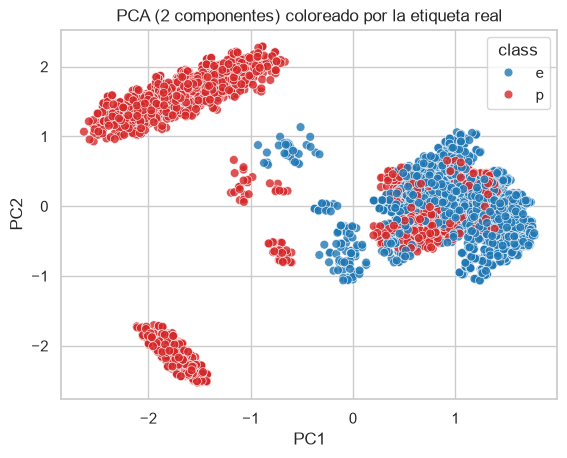

In [14]:
pca = PCA(n_components= 2)         # nos quedamos con 2 componentes para poder pintarlas
pca.fit(X_train)                    # PCA aprende las direcciones de máxima varianza

X_pca = pca.transform(X_train)      # proyectamos X_train a 2D
print("Varianza explicada:", pca.explained_variance_ratio_)

# Representar en un scatterplot y poner en color las etiquetas de entrenamiento
colores = {"e": "#1f77b4", "p": "#d62728"}   # azul = comestible, rojo = venenosa
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train,
                palette=colores, alpha=0.8, s=40,
                edgecolor="white", linewidth=0.5)   # borde blanco fino → cada punto se distingue
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA (2 componentes) coloreado por la etiqueta real")
plt.legend(title="class", labels=None)
plt.show()

Parece que está bastante separadito, ¡a ojo mucho se puede ver! :)

> **📝 Observación:** Las 2 primeras componentes explican solo el **≈ 30 % de la varianza** (16,9 % + 12,7 %).
> Aun así, se ven **grupos bien definidos** y muchos son de un solo color (p. ej. dos grupos totalmente venenosos a la izquierda),
> sin que PCA haya usado la etiqueta. En el grupo grande de la derecha, en cambio, comestibles y venenosas se mezclan:
> 2 componentes no bastan para separarlas del todo.

Antes de seguir, entrenamos un clasificador supervisado como **línea base** (así sabemos cuánta información hay realmente en los datos).

**¿Por qué un modelo supervisado en un taller de clustering?**

Antes de agrupar sin etiquetas, queremos saber **cuánta información hay realmente** en los datos para distinguir comestibles de venenosas.
Random Forest **sí ve la etiqueta**: es como el profesor que resuelve el examen con la hoja de respuestas.
Su resultado marca el **techo** (lo mejor que se puede conseguir). Después compararemos cuánto se acerca el clustering **sin ver la etiqueta**.

- **Modelo:** `RandomForestClassifier` con 100 árboles (*ensemble*: cada árbol vota y gana la mayoría).
- **Entrenamiento** en `X_train` y **evaluación** en `X_test` (setas que el modelo no ha visto).
- **Métrica:** *accuracy* (proporción de aciertos). Como las clases están equilibradas (52 % / 48 %), la accuracy es fiable aquí.

In [15]:
# 1. Definir el clasificador y el numero de estimadores
rf = RandomForestClassifier(n_estimators=100, random_state=42)   # 100 árboles de decisión

# 2. Entrenar en train
rf.fit(X_train, y_train)          # aquí SÍ usamos la etiqueta (modelo supervisado)

# 3. Calcular la precision sobre test
acc = rf.score(X_test, y_test)    # accuracy sobre datos que el modelo no ha visto
print(f"Accuracy Random Forest (test): {acc:.4f}")

Accuracy Random Forest (test): 1.0000


Es un conjunto sencillo y Random Forest es muy bueno. Veamos cuántas features tenemos:

> **📝 Observación:** Random Forest obtiene una **accuracy de 1.0 (100 %)** en test.
> No es *data leakage*: `class` no está en `X` y el test no se usó para entrenar. Simplemente el dataset es muy separable
> (por ejemplo, `odor` por sí sola ya distingue casi todas las setas).
> Conclusión: **la información para separar comestibles y venenosas existe**. El techo es 100 %.

In [16]:
X_train.shape

(5443, 115)

¿Muchas features, no? Vamos a reducirlas con PCA y ver cuántas componentes necesita Random Forest para mantener su precisión.

**Objetivo:** averiguar con **cuántas componentes PCA** Random Forest mantiene la accuracy del 100 % obtenida con las 115 columnas.

**Cómo lo hacemos:** probamos distintos números de componentes (1, 2, 3… 30). Para cada uno:
1. Ajustamos PCA **solo con `X_train`** y proyectamos `X_test` con ese mismo PCA (`transform`), para que la información del test **no se filtre** en el entrenamiento.
2. Entrenamos un Random Forest con los datos reducidos.
3. Guardamos la accuracy en test.

Al final pintamos **nº de componentes vs accuracy** para ver a partir de qué punto ya no merece la pena añadir más.

**¿Por qué nos interesa?** Menos dimensiones = modelos más rápidos y menos ruido. Además, el clustering lo haremos sobre una versión reducida con PCA.


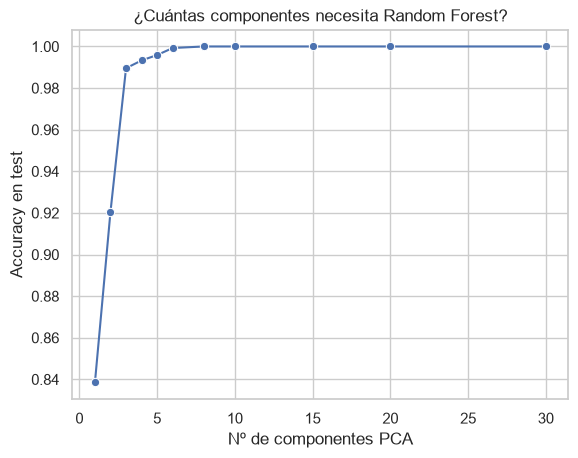

{1: 0.8385, 2: 0.9206, 3: 0.9896, 4: 0.9933, 5: 0.9959, 6: 0.9993, 8: 1.0, 10: 1.0, 15: 1.0, 20: 1.0, 30: 1.0}


In [17]:
n_features = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30]   # nº de componentes a probar
scores = []

for n in n_features:
    # 1. Definir y ajustar PCA sobre X_train
    pca_n = PCA(n_components=n, random_state=42)
    X_train_pca = pca_n.fit_transform(X_train)   # aprende y proyecta train
    X_test_pca = pca_n.transform(X_test)         # test: solo proyectar (sin aprender)

    # 2. Entrenar Random Forest sobre los datos reducidos
    rf_n = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_n.fit(X_train_pca, y_train)

    # 3. Guardar el score en test
    scores.append(rf_n.score(X_test_pca, y_test))

sns.lineplot(x=list(n_features), y=scores, marker="o")
plt.xlabel("Nº de componentes PCA"); plt.ylabel("Accuracy en test")
plt.title("¿Cuántas componentes necesita Random Forest?")
plt.show()

print(dict(zip(n_features, [round(s, 4) for s in scores])))   # tabla número → accuracy

A partir de ~10 componentes ya tenemos la precisión que queríamos, reduciendo las variables a una fracción de las originales.

> **📝 Observación:** Con **1 sola componente** Random Forest ya acierta el 83,9 %, con **3** el 99 %,
> y a partir de **8 componentes** alcanza el **100 %**, igual que con las 115 columnas originales.
> Es decir, podemos reducir las dimensiones en un **~93 %** sin perder capacidad predictiva:
> la información relevante está concentrada en pocas direcciones.
> Por eso, para el clustering usaremos **PCA con 10 componentes** (`X_red`): margen suficiente, menos ruido y algoritmos más rápidos.

---
## t-SNE: reducción **no lineal** para visualizar

PCA es lineal. **t-SNE** intenta preservar la vecindad local y suele separar mejor los grupos visualmente. Es más caro, así que lo calculamos sobre una **muestra**.

**¿En qué se diferencia de PCA?**

| | PCA | t-SNE |
|---|---|---|
| Tipo | Lineal (ejes rectos) | **No lineal** |
| Qué conserva | Estructura global, distancias grandes | **Vecindad local**: quién está cerca de quién |
| Velocidad | Muy rápido | Lento → usamos una **muestra** (2000 setas) |
| Uso | Visualizar **y** modelar | **Solo visualizar** (no tiene `transform` para datos nuevos) |

**Analogía:** PCA hace una *foto* de la clase desde el mejor ángulo; t-SNE sienta juntos a los alumnos que son "amigos".
Los grupos se ven muy claros, pero **la distancia entre grupos no tiene significado**: solo importa quién está junto a quién.

**Parámetros:**
- `perplexity=30` → aproximadamente a cuántos vecinos "mira" cada punto (valor por defecto).
- `init="pca"` → empieza desde la proyección PCA, más estable.
- `random_state=42` → resultados reproducibles.

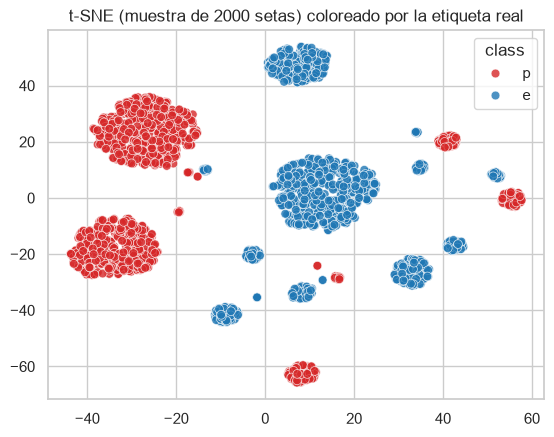

In [18]:
# 1. Tomar una muestra de X_train (t-SNE es lento)
X_sample = X_train.sample(2000, random_state=42)   # 2000 setas al azar
y_sample = y_train.loc[X_sample.index]             # sus etiquetas (mismas filas)

# 2. Definir TSNE(n_components=2, ...) y ajustar
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42)
X_tsne = tsne.fit_transform(X_sample)              # 115 dimensiones → 2

# 3. Pintar el embedding coloreado por la etiqueta
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_sample,
                palette=colores, alpha=0.8, s=40, edgecolor="white", linewidth=0.5)
plt.title("t-SNE (muestra de 2000 setas) coloreado por la etiqueta real")
plt.show()

> **📝 Observación:** t-SNE separa los datos mucho mejor que PCA: aparecen **muchos grupos pequeños (~15) y casi todos de un solo color**.
> El grupo mezclado que veíamos en PCA aquí se divide en varios grupos puros.
> Interpretación: las setas no forman solo 2 grupos, sino **muchos subgrupos naturales** (probablemente especies parecidas),
> y cada uno es o comestible o venenoso. Esto será importante al elegir el número de clusters (k).
> *(Recordatorio: en t-SNE solo importa quién está junto a quién; la distancia entre grupos no tiene significado.)*

---
## Clustering

El conjunto es sencillito, así que probemos clustering para ver qué información obtenemos **sin usar las etiquetas**. Trabajaremos sobre una representación reducida con PCA (10 componentes), que limpia ruido y acelera los algoritmos.

Para el clustering usamos **todo `X`** (sin separar train/test): el clustering no aprende de la etiqueta,
así que no hay nada que "memorizar" ni que evaluar en un examen. Solo buscamos grupos en los datos.
Reducimos a **10 componentes**, ya que vimos que con 8 Random Forest alcanzaba el 100 %.

In [19]:
# Reducir X (one-hot completo) a 10 componentes con PCA -> X_red
pca_10 = PCA(n_components=10, random_state=42)
X_red = pca_10.fit_transform(X)              # todas las setas (sin separar train/test)
print(X_red.shape)
print("Varianza explicada acumulada:", pca_10.explained_variance_ratio_.sum().round(3))

(8124, 10)
Varianza explicada acumulada: 0.645


> **📝 Observación:** `X_red` tiene 8124 filas × 10 componentes y conserva el **64,5 % de la varianza**.
> Aunque perdemos un 35 % de varianza, vimos que con 8 componentes Random Forest ya acertaba el 100 %:
> la información que perdemos es sobre todo **ruido** que no ayuda a separar las clases.

### K-Means: ¿cuántos clusters? Codo + Silhouette

El **método del codo** mira la inercia (suma de distancias a los centroides). El **coeficiente de silhouette** mide cómo de bien separados están los clusters (cuanto más alto, mejor). Usamos ambos.

K-Means necesita que le digamos **cuántos grupos (k)** buscar. Para elegir k usamos dos herramientas:

| Método | Qué mide | Qué buscamos |
|---|---|---|
| **Codo** (inercia) | Suma de distancias de cada punto a su centroide | El punto donde la curva "dobla" (el codo): a partir de ahí, añadir clusters mejora poco |
| **Silhouette** | Lo bien separados que están los clusters (de -1 a 1) | El valor **más alto** |

Probamos **k de 2 a 15**: aunque sabemos que hay 2 clases (e/p), en t-SNE vimos **muchos subgrupos**, así que no damos por hecho que k = 2 sea lo mejor.

- `n_init=10` → K-Means se ejecuta con 10 inicializaciones distintas y se queda con la mejor (evita malos resultados por azar).
- Trabajamos sobre `X_red` (PCA con 10 componentes).

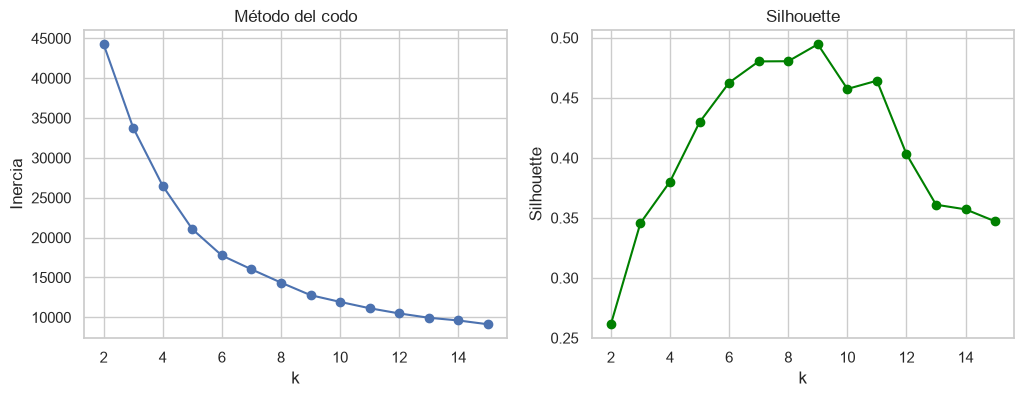

Mejor k según silhouette: 9


In [20]:
from sklearn.cluster import KMeans

k_values = range(2, 16)                     # probamos de 2 a 15 clusters
inercias, silhouettes = [], []
for k in k_values:
    # Definir KMeans y ajustar sobre X_red
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_red)
    # Guardar la inercia (km.inertia_) y el silhouette_score
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_red, labels))

# Pintar las dos curvas (codo y silhouette)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inercias, marker="o")
axes[0].set(title="Método del codo", xlabel="k", ylabel="Inercia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="green")
axes[1].set(title="Silhouette", xlabel="k", ylabel="Silhouette")
plt.show()

print("Mejor k según silhouette:", list(k_values)[np.argmax(silhouettes)])

> **📝 Observación:** El **codo no es claro** (la curva baja de forma suave; quizá un ligero cambio entre k = 2 y 4),
> algo habitual con datos reales. Por eso nos apoyamos en el **silhouette**, que es máximo en **k = 9** (0,495).
> Esto coincide con lo visto en t-SNE: las setas forman **muchos subgrupos naturales**, no solo 2.
> Aun así, en el siguiente paso usaremos **k = 2** para comprobar si K-Means recupera la división comestible/venenosa.

### K-Means final y comparación con la etiqueta

Sabemos que hay dos clases (comestible / venenosa), así que probamos `k=2`. Con `catplot` vemos la distribución de la etiqueta real dentro de cada cluster.

K-Means busca **2 grupos sin ver la etiqueta**. Después "abrimos el sobre" 📩 y comparamos los clusters con la clase real.

**Catplot:** un gráfico por cluster que cuenta cuántas setas `e` y `p` hay dentro.
- Ideal: cada cluster contiene **solo una clase**.
- Malo: ambos clusters mezclan comestibles y venenosas a partes iguales.

**Métricas de comparación con la etiqueta** (de 0 a 1):

| Métrica | Qué mide | 0 | 1 |
|---|---|---|---|
| **ARI** (*Adjusted Rand Index*) | Si las parejas de setas que están juntas en el cluster también lo están en la etiqueta, **corregido por azar** | Agrupación aleatoria | Coincidencia perfecta |
| **NMI** (*Normalized Mutual Information*) | Cuánta información sobre la clase nos da saber el cluster | Ninguna | Toda |

⚠️ Los números de cluster (0/1) son **arbitrarios**: "cluster 0" no significa "comestible". ARI y NMI no miran los números, sino **quién está con quién**.

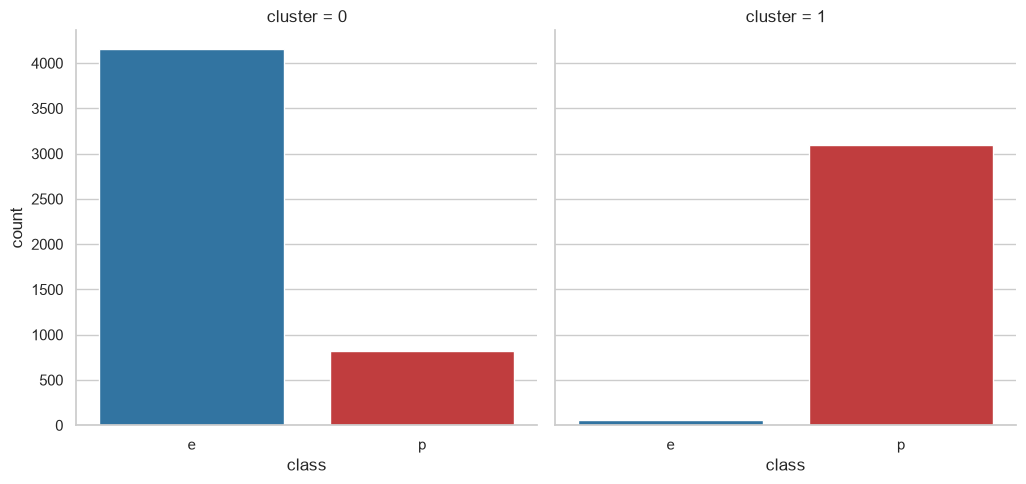

ARI: 0.617
NMI: 0.566


In [21]:
# Aprender KMeans con el k obtenido y preparar el catplot.
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters_km = kmeans.fit_predict(X_red)            # cluster de cada seta (0 o 1), SIN ver la etiqueta

df_res = pd.DataFrame({"cluster": clusters_km, "class": y})   # cluster encontrado + etiqueta real

ax = sns.catplot(col="cluster", x="class", data=df_res, kind="count",
                 col_wrap=4, palette=colores, order=["e", "p"])
plt.show()

# Ahora sí abrimos el sobre: comparamos clusters con la etiqueta real
print("ARI:", round(adjusted_rand_score(y, clusters_km), 3))
print("NMI:", round(normalized_mutual_info_score(y, clusters_km), 3))

> **ARI / NMI** comparan los clusters con la etiqueta real (0 = aleatorio, 1 = idéntico). Sin haber visto la etiqueta, K-Means recupera buena parte de la estructura comestible/venenosa, pero **no es perfecto**: ese es el reto real del no supervisado.

> **📝 Observación:** Sin ver la etiqueta, K-Means (k = 2) obtiene **ARI = 0,617** y **NMI = 0,566**: recupera buena parte de la estructura, pero no toda.
> - **Cluster 0** mezcla 4153 comestibles con **816 venenosas** (≈ 16 %).
> - **Cluster 1** es casi puro: 3100 venenosas y solo 55 comestibles (≈ 98 % venenosas).
>
> Comparado con Random Forest (100 %), queda lejos: es normal, porque K-Means **no ve la etiqueta** y solo agrupa por similitud.
> Además, como vimos con silhouette (k = 9) y t-SNE, los datos tienen **muchos subgrupos naturales**; al forzar k = 2,
> algunos subgrupos venenosos acaban en el cluster "comestible".
> ⚠️ En la práctica, un cluster "comestible" con un 16 % de setas venenosas **no sería seguro** para decidir qué setas comer.

### Comparativa de algoritmos de clustering

Vamos a poner a competir **K-Means, Aglomerativo, GMM y DBSCAN** con varias métricas. Las tres primeras métricas son *internas* (no usan etiqueta); ARI sí la usa, para validar.

**Los 4 algoritmos:**

| Algoritmo | Cómo agrupa | ¿Le damos k? |
|---|---|---|
| **K-Means** | Asigna cada punto al **centroide** más cercano | Sí |
| **Aglomerativo** | Cada punto empieza solo y los grupos más cercanos se van **uniendo paso a paso** | Sí |
| **GMM** | Modela los grupos como **nubes de probabilidad** (gaussianas) | Sí |
| **DBSCAN** | Las zonas **densas** son grupos; los puntos aislados son ruido (`-1`) | **No**: le damos `eps` (radio de vecindad) |

**Las métricas:**

| Métrica | ¿Usa la etiqueta? | Mejor si es… |
|---|---|---|
| Silhouette | No (interna) | **Alta** ↑ |
| Davies-Bouldin | No (interna) | **Baja** ↓ |
| Calinski-Harabasz | No (interna) | **Alta** ↑ |
| ARI | **Sí** (abrimos el sobre 📩) | **Alta** ↑ |

Definimos una **función `evaluar()`** para no repetir el mismo cálculo cuatro veces, y la aplicamos a cada modelo sobre `X_red`.
Usamos **k = 2** en los tres primeros (para comparar con comestible/venenosa) y `eps = 1.5` en DBSCAN
(con valores más pequeños aparecían cientos de grupos diminutos o demasiado ruido).

In [22]:
# Definir una funcion evaluar(nombre, labels, X) que devuelva silhouette,
# davies_bouldin, calinski_harabasz y ARI.
def evaluar(nombre, labels, X):
    """Calcula las métricas de un clustering y las devuelve en un diccionario."""
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)   # DBSCAN marca el ruido con -1
    return {
        "modelo": nombre,
        "n_clusters": n_clusters,
        "silhouette ↑": silhouette_score(X, labels),
        "davies_bouldin ↓": davies_bouldin_score(X, labels),
        "calinski_harabasz ↑": calinski_harabasz_score(X, labels),
        "ARI ↑": adjusted_rand_score(y, labels),               # el único que usa la etiqueta
    }

# Aplicarla a KMeans, AgglomerativeClustering, GaussianMixture y DBSCAN
modelos = {
    "K-Means":     KMeans(n_clusters=2, n_init=10, random_state=42),
    "Aglomerativo": AgglomerativeClustering(n_clusters=2),
    "GMM":         GaussianMixture(n_components=2, random_state=42),
    "DBSCAN":      DBSCAN(eps=1.5, min_samples=10),
}

resultados = []
for nombre, modelo in modelos.items():
    labels = modelo.fit_predict(X_red)
    resultados.append(evaluar(nombre, labels, X_red))

# y montar una tabla (DataFrame) comparativa.
tabla = pd.DataFrame(resultados).set_index("modelo").round(3)
tabla

,n_clusters,silhouette ↑,davies_bouldin ↓,calinski_harabasz ↑,ARI ↑
modelo,,,,,
K-Means,2,0.261,1.693,2564.691,0.617
Aglomerativo,2,0.259,1.696,2503.625,0.609
GMM,2,0.258,1.701,2500.017,0.599
DBSCAN,6,0.358,1.071,2304.340,0.374


> **📝 Observación:**
> - **K-Means, Aglomerativo y GMM dan resultados casi idénticos** (ARI ≈ 0,60–0,62, silhouette ≈ 0,26):
>   tres métodos distintos encuentran la misma estructura, lo que indica que es **real** y no casualidad.
>   K-Means es ligeramente el mejor en ARI (0,617) y Calinski-Harabasz.
> - **DBSCAN encuentra 6 clusters** y gana en las métricas **internas** (silhouette 0,358, Davies-Bouldin 1,071),
>   pero es el **peor en ARI** (0,374).
> - **¿Contradicción?** No: las métricas responden a preguntas distintas. Las internas miden si los grupos están
>   **bien separados**; ARI mide si coinciden con **comestible/venenosa**. DBSCAN encuentra subgrupos densos reales
>   (como los de t-SNE), pero 6 grupos no encajan con 2 clases.
> - **Conclusión:** no hay un "mejor algoritmo" absoluto; depende de **qué pregunta** queremos responder.

### Dendrograma (clustering jerárquico)

El clustering aglomerativo construye una jerarquía que podemos visualizar como **dendrograma**. La altura a la que se unen dos grupos indica cómo de distintos son. Lo calculamos sobre una muestra para que se lea bien.

**¿Qué es un dendrograma?** Un "árbol genealógico" que muestra cómo el clustering aglomerativo va uniendo grupos:

- **Abajo:** cada seta es una hoja independiente 🍃
- **Al subir:** se unen primero las más parecidas, luego esos grupos entre sí…
- **Arriba del todo:** todas las setas en un único grupo.
- **Altura de las líneas verticales:** lo **distintos** que eran los dos grupos al unirse. Una línea vertical larga = se unieron grupos muy diferentes.

**Cómo leerlo:** se "corta" el árbol con una línea horizontal ✂️. El nº de líneas verticales que cruza = nº de clusters.
El mejor corte suele estar donde las líneas verticales son **más largas**.

**Analogía:** alumnos → compañeros de pupitre → mesas de trabajo → clases → colegio 🏫. Según el nivel en que cortes, obtienes más o menos grupos.

**Parámetros:**
- Usamos una **muestra de 500 setas**: con 8124 hojas el gráfico sería ilegible.
- `method="ward"` → une los grupos que menos aumentan la varianza interna (grupos compactos).
- `truncate_mode="lastp", p=30` → solo se muestran las 30 últimas uniones (los números entre paréntesis indican cuántas setas hay en cada rama).

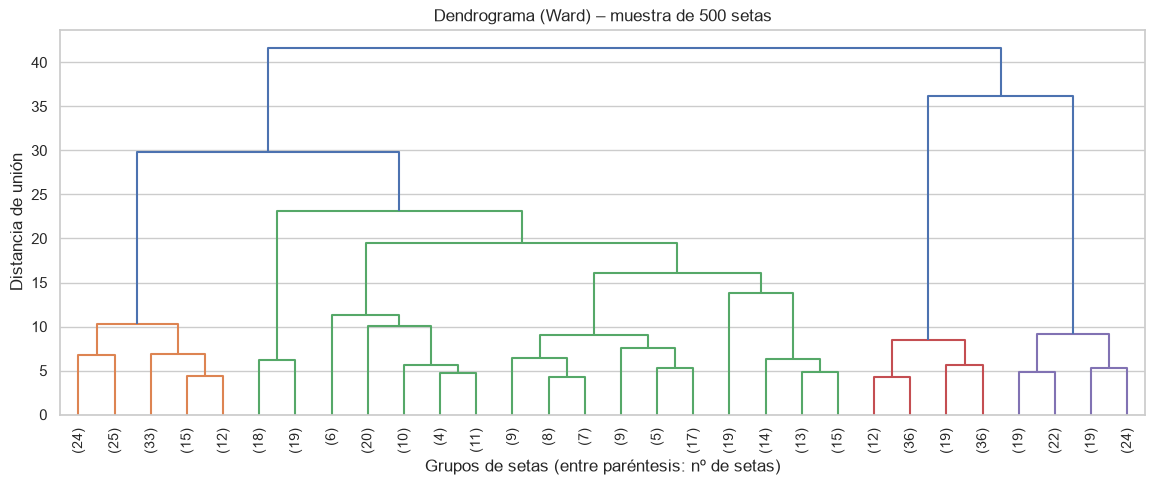

In [23]:
# 1. Tomar una muestra de X_red
rng = np.random.default_rng(42)
idx = rng.choice(len(X_red), size=500, replace=False)   # 500 setas al azar (el dendrograma completo sería ilegible)
X_muestra = X_red[idx]

# 2. linkage(..., method='ward')
Z = linkage(X_muestra, method="ward")   # ward: une los grupos que menos aumentan la varianza interna

# 3. dendrogram(...) para visualizar la jerarquia
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)   # mostramos solo las 30 últimas uniones
plt.title("Dendrograma (Ward) – muestra de 500 setas")
plt.xlabel("Grupos de setas (entre paréntesis: nº de setas)")
plt.ylabel("Distancia de unión")
plt.grid(axis="x", visible=False)   # sin líneas verticales de fondo
plt.show()

> **📝 Observación:** El dendrograma muestra **2 grandes ramas** en la parte superior (las uniones más altas, ~30–42),
> lo que encaja con las 2 clases (comestible/venenosa). Si cortamos más abajo (~25) aparecen **4 grupos** (los colores),
> y la rama verde se divide en **muchos subgrupos pequeños**, coherente con el silhouette (k = 9) y con t-SNE.
> Es decir, la estructura es **jerárquica**: dos grandes familias que a su vez contienen varios subgrupos.
> *(Usamos una muestra de 500 setas y mostramos solo las 30 últimas uniones; con 150 setas sin truncar se obtiene la misma forma general.)*

### DBSCAN: la **métrica de distancia importa**

DBSCAN agrupa por densidad. Pero con datos **categóricos** codificados en one-hot, la distancia euclídea no captura bien la similitud. Comparemos euclídea (sobre PCA) con la distancia de **Jaccard** (pensada para datos binarios).

**Euclídea vs Jaccard con datos one-hot:**
- **Euclídea:** cuenta en cuántas columnas difieren dos setas, y trata los **0 compartidos** como similitud.
- **Jaccard:** solo mira las columnas con **1**: *de las características que tienen, ¿qué proporción comparten?*

**Analogía:** hay 100 hobbies posibles. Ana: pintura y fútbol. Carlos: pintura y guitarra.
Para la euclídea se parecen muchísimo porque **ninguno hace buceo, ni ajedrez, ni…** (98 ceros en común).
Jaccard solo mira lo que sí tienen: 1 hobby común de 3 → similitud 1/3. En one-hot casi todo son ceros, así que Jaccard tiene más sentido.

Además de ARI, medimos la **homogeneidad** (0–1): ¿cada cluster contiene **una sola clase**? Es útil aquí porque DBSCAN
encuentra muchos subgrupos, y ARI penaliza tener más de 2 clusters aunque sean puros.

In [24]:
# Comparar DBSCAN con metric='euclidean' (sobre X_red) y metric='jaccard'
# (sobre el one-hot binario). Observar cual recupera mejor la estructura (ARI).
from sklearn.metrics import homogeneity_score

X_bin = X.values.astype(bool)   # one-hot como True/False (Jaccard trabaja con datos binarios)

configs = [
    ("Euclídea (X_red)", X_red, "euclidean", 0.5),
    ("Euclídea (X_red)", X_red, "euclidean", 1.0),
    ("Euclídea (X_red)", X_red, "euclidean", 1.5),
    ("Euclídea (X_red)", X_red, "euclidean", 2.0),
    ("Jaccard (one-hot)", X_bin, "jaccard", 0.2),
    ("Jaccard (one-hot)", X_bin, "jaccard", 0.3),
    ("Jaccard (one-hot)", X_bin, "jaccard", 0.4),
    ("Jaccard (one-hot)", X_bin, "jaccard", 0.5),
]

filas = []
for nombre, datos, metrica, eps in configs:
    labels = DBSCAN(eps=eps, min_samples=10, metric=metrica).fit_predict(datos)
    filas.append({
        "distancia": nombre,
        "eps": eps,
        "n_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "ruido (-1)": (labels == -1).sum(),
        "ARI ↑": adjusted_rand_score(y, labels),
        "homogeneidad ↑": homogeneity_score(y, labels),   # ¿cada cluster tiene una sola clase?
    })

pd.DataFrame(filas).round(3)

,distancia,eps,n_clusters,ruido (-1),ARI ↑,homogeneidad ↑
0,Euclídea (X_red),0.5,130,690,0.021,0.918
1,Euclídea (X_red),1.0,36,24,0.175,0.932
2,Euclídea (X_red),1.5,6,0,0.374,0.703
3,Euclídea (X_red),2.0,4,0,0.080,0.283
4,Jaccard (one-hot),0.2,19,16,0.275,0.989
5,Jaccard (one-hot),0.3,14,16,0.262,0.819
6,Jaccard (one-hot),0.4,5,8,0.443,0.575
7,Jaccard (one-hot),0.5,3,5,-0.001,0.028


> **Lección:** con datos categóricos, elegir la distancia adecuada (Jaccard/Hamming) puede cambiar por completo el resultado de un algoritmo basado en densidad. No hay un algoritmo que gane siempre: depende del tipo de datos.

> **📝 Observación:**
> - **Jaccard gana en ambas métricas.** Con `eps = 0.2` encuentra **19 clusters casi perfectamente puros** (homogeneidad **0,989**):
>   cada grupo es prácticamente todo comestible o todo venenoso. Son los **subgrupos naturales** que ya veíamos en t-SNE.
> - Para acercarse a esa pureza, la euclídea necesita **36 clusters** y aun así queda por debajo (0,932).
> - En ARI, el mejor resultado también es de Jaccard (`eps = 0.4`: **0,443** frente a 0,374 de la euclídea).
> - **Compromiso:** con menos clusters sube el ARI (nos acercamos a las 2 clases) pero baja la homogeneidad (se mezclan subgrupos).
> - ARI es bajo en todos los casos porque DBSCAN encuentra **subgrupos**, no las 2 clases; por eso la homogeneidad cuenta mejor la historia aquí.
> - **DBSCAN es muy sensible a `eps`:** si es demasiado pequeño, los datos se fragmentan en cientos de grupos y mucho ruido
>   (euclídea 0.5: 130 clusters, 690 puntos de ruido); si es demasiado grande, todo se fusiona y el ARI se desploma
>   (euclídea 2.0: 0,080; Jaccard 0.5: −0,001). Hay que probar varios valores.
>
> **Conclusión:** con datos categóricos en one-hot, **la distancia importa**: Jaccard, pensada para datos binarios, describe mejor la similitud entre setas.

### Visualización final: clusters vs etiqueta real

Repetimos el scatter PCA, pero coloreando por el cluster de K-Means y por la etiqueta real, lado a lado.

Proyectamos **todas las setas** con PCA (2 componentes) y pintamos el mismo gráfico dos veces:
- **Izquierda:** los clusters de K-Means (k = 2), encontrados **sin ver la etiqueta**.
- **Derecha:** la etiqueta real (comestible / venenosa).

Cuanto más se parezcan los dos gráficos, mejor ha recuperado K-Means la estructura real.
En el gráfico de clusters usamos colores **neutros** (morado/naranja) y no azul/rojo, porque el número de cluster
es arbitrario: "cluster 0" **no significa** "comestible".

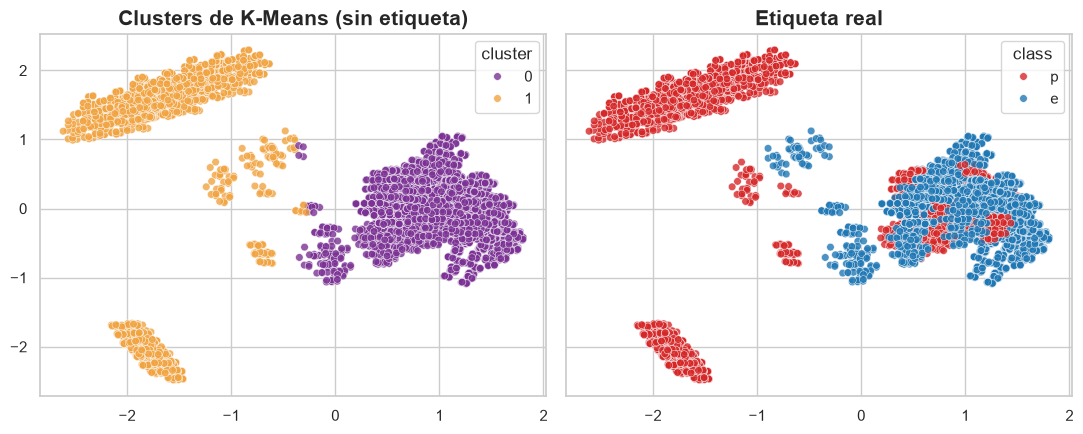

In [25]:
# Entrenar PCA(2) sobre X para representar.
pca_vis = PCA(n_components=2, random_state=42)
X_vis = pca_vis.fit_transform(X)                     # todas las setas en 2D

# Pintar dos scatter: uno coloreado por el cluster de KMeans y otro por la etiqueta real.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

sns.scatterplot(x=X_vis[:, 0], y=X_vis[:, 1], hue=clusters_km, palette=["#7b3294", "#f1a340"],
                alpha=0.8, s=30, edgecolor="white", linewidth=0.4, ax=axes[0])
axes[0].set_title("Clusters de K-Means (sin etiqueta)", fontsize=15, fontweight="bold")
axes[0].legend(title="cluster")

sns.scatterplot(x=X_vis[:, 0], y=X_vis[:, 1], hue=y, palette=colores,
                alpha=0.8, s=30, edgecolor="white", linewidth=0.4, ax=axes[1])
axes[1].set_title("Etiqueta real", fontsize=15, fontweight="bold")
axes[1].legend(title="class")


plt.tight_layout()
plt.show()

Es bastante parecido, ¿no? No es tan bueno como Random Forest (que usa etiquetas), pero K-Means ha identificado bastante bien la estructura **sin usarlas**. Si no tuviéramos etiquetas, esta aproximación nos ayudaría mucho a clasificar los tipos de hongos.

> **📝 Observación:** Los dos gráficos se parecen mucho:
> - Los **grupos de la izquierda** (arriba y abajo) son todos venenosos y K-Means los pone **todos en el mismo cluster** ✅
> - El **grupo grande de la derecha** es un único cluster para K-Means, pero en realidad contiene **islas de setas venenosas**
>   (las 816 venenosas del cluster "comestible") ❌
> - Algunos **grupos pequeños comestibles** del centro acaban en el cluster "venenoso" (las 55 comestibles mal agrupadas).
>
> K-Means separa bien los grupos **lejanos**, pero no puede separar los que se **solapan** en el espacio: ahí está el límite
> de un método sin etiquetas, y la razón de que el ARI sea 0,62 y no 1.

---
## Detección de anomalías (Isolation Forest)

Una tarea no supervisada distinta: encontrar las muestras **atípicas**. Isolation Forest aísla los puntos raros con pocos cortes aleatorios.

Isolation Forest no busca grupos, sino **setas raras**. Funciona como el juego de las "20 preguntas":
hace cortes aleatorios ("¿olor = n?", "¿color = w?"…). Una seta **normal** está rodeada de muchas parecidas y hacen falta
**muchas preguntas** para aislarla; una seta **rara** se queda sola con **pocas preguntas** → anomalía.

- `contamination=0.05` → le decimos que esperamos un **5 %** de anomalías (≈ 400 setas).**Es una decisión nuestra**, no algo que el algoritmo descubra.
- `predict` devuelve **-1** para las anomalías y **1** para las normales.
- Ajustamos sobre `X_red` y pintamos el resultado sobre la proyección PCA en 2D (`X_vis`).

Nº de anomalías: 407
Clase de las anomalías:
 class
e    324
p     83
Name: count, dtype: int64


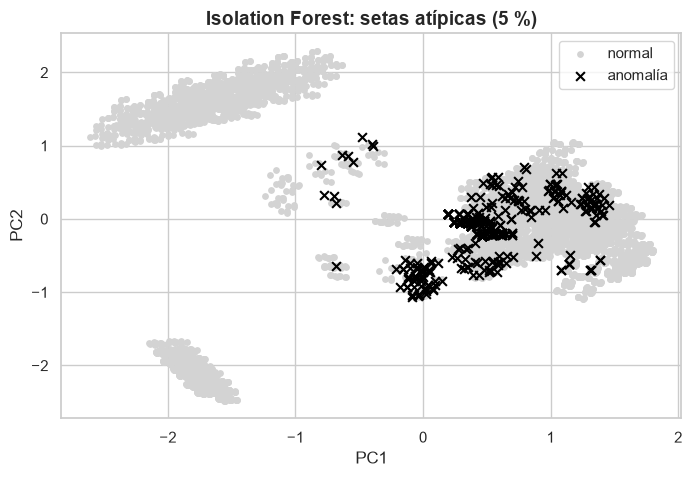

In [26]:
# 1. Definir IsolationForest(contamination=...) y ajustar sobre X_red
iso = IsolationForest(contamination=0.05, random_state=42)

# 2. predict -> -1 son anomalias
pred_iso = iso.fit_predict(X_red)
anomalias = pred_iso == -1                      # True = seta atípica
print("Nº de anomalías:", anomalias.sum())
print("Clase de las anomalías:\n", y[anomalias].value_counts())   # abrimos el sobre: ¿son comestibles o venenosas?

# 3. Pintarlas sobre la proyeccion PCA
plt.figure(figsize=(8, 5))
plt.scatter(X_vis[~anomalias, 0], X_vis[~anomalias, 1], c="lightgrey", s=15, label="normal")
plt.scatter(X_vis[anomalias, 0], X_vis[anomalias, 1], c="black", marker="x", s=40, label="anomalía")
plt.title("Isolation Forest: setas atípicas (5 %)", fontsize=14, fontweight="bold")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend()

> **📝 Observación:** Con `contamination = 0.05` se detectan **407 setas atípicas** (5 %): **324 comestibles y 83 venenosas**.
> - **Ninguna anomalía** en los dos grandes grupos venenosos de la izquierda: son grupos muy **densos y homogéneos**.
> - Las anomalías se concentran en la **zona central y derecha**, donde hay subgrupos pequeños y más variedad.
> - Algunas parecen estar "dentro" del grupo grande: Isolation Forest trabaja en **10 dimensiones** y aquí solo vemos 2 (30 % de la varianza).
> - **¿Las anomalías son más venenosas?** No: el 80 % son comestibles (y con `contamination = 0.02`, el 94 %).
>   Las setas más raras parecen ser **especies poco frecuentes**, no especialmente peligrosas. **Raro ≠ venenoso.**

---
## Para ir más allá (opcional)

- **UMAP** (`pip install umap-learn`): alternativa a t-SNE, más rápida y preserva mejor la estructura global.
- **HDBSCAN** (`pip install hdbscan`): DBSCAN jerárquico que no necesita fijar `eps`.
- **Reglas de asociación** (`mlxtend`, Apriori/FP-Growth): muy naturales aquí por ser datos categóricos; permiten descubrir reglas tipo «si olor = X entonces venenosa».

## 🚀 Extra: Para ir más allá

### HDBSCAN: DBSCAN sin elegir `eps`

Con DBSCAN tuvimos que **probar muchos `eps`** a mano, y el resultado cambiaba mucho con cada valor.
**HDBSCAN** (DBSCAN jerárquico) prueba **todos los radios a la vez** y se queda con los clusters más **estables**. Solo pide:
- **`min_cluster_size`**: el tamaño mínimo para considerar algo un cluster.

Viene incluido en scikit-learn (≥ 1.3), no hace falta instalar nada. Usamos la distancia **Jaccard** sobre el one-hot (`X_bin`), que fue la que mejor funcionó con DBSCAN, y probamos varios tamaños mínimos.

In [27]:
from sklearn.cluster import HDBSCAN

filas = []
for m in [20, 50, 100]:                                   # tamaño mínimo de cluster
    hdb = HDBSCAN(min_cluster_size=m, metric="jaccard", copy=True)   # copy=True: no modifica X_bin
    labels = hdb.fit_predict(X_bin)                       # -1 = ruido
    no_ruido = labels != -1
    filas.append({"min_cluster_size": m,
                  "clusters": len(set(labels)) - (1 if -1 in labels else 0),
                  "ruido": (~no_ruido).sum(),
                  "ARI": round(adjusted_rand_score(y_bin, labels), 3),          # vs etiqueta real
                  "homogeneidad": round(homogeneity_score(y_bin[no_ruido], labels[no_ruido]), 3)})  # pureza (sin ruido)
pd.DataFrame(filas)

,min_cluster_size,clusters,ruido,ARI,homogeneidad
0,20,18,53,0.275,0.994
1,50,10,148,0.260,0.799
2,100,10,584,0.263,0.895


> **📝 Observación:**
> - Con **`min_cluster_size = 20`**: **18 clusters**, solo **53 setas de ruido** y **homogeneidad 0,994** → casi cada cluster es de una sola clase.
>   Es prácticamente lo mismo que el mejor DBSCAN Jaccard (eps 0,2: 19 clusters, 0,989), pero **sin tener que buscar `eps` a mano**.
> - Con tamaños mínimos más grandes (50, 100) se unen familias distintas: menos clusters, más ruido y **menos pureza**.
> - El **ARI es bajo (≈ 0,27)** porque compara 18 grupos con solo 2 clases; la homogeneidad muestra que esos 18 grupos son **puros**.
>   Confirma lo que vimos en t-SNE: las setas forman **muchas "familias" pequeñas**, no 2 grupos.
> - Ventaja de HDBSCAN: `min_cluster_size` es **más fácil de elegir** que `eps` (“¿cuántas setas como mínimo para hablar de una familia?”).

### Reglas de asociación (Apriori)

Las setas son datos **categóricos**, ideales para buscar reglas del tipo **«si olor = X → venenosa»**. Usamos `mlxtend` (`pip install mlxtend`):
1. **One-hot de todo el `df`** (incluida `class`): cada columna es un "ítem" verdadero/falso.
2. **`apriori`** encuentra las combinaciones de ítems **frecuentes** (`min_support`).
3. **`association_rules`** convierte esas combinaciones en reglas y las mide:
   - **support**: % de setas donde se cumple la regla completa → ¿es **común**?
   - **confidence**: de las setas que cumplen la condición, % que tiene el resultado → ¿es **fiable**?
   - **lift**: cuántas veces mejora la predicción respecto a no saber nada (1 = no aporta).

Nos quedamos con las reglas **simples** (una condición → clase) con **confidence ≥ 95 %**.

⚠️ Aquí **sí usamos la etiqueta** `class`: es un análisis **descriptivo** para entender qué rasgos van unidos a cada clase, no un clustering.

In [28]:
from mlxtend.frequent_patterns import apriori, association_rules

# 1. One-hot de todo el df (con 'class') en True/False
items = pd.get_dummies(df).astype(bool)          # ej. 'odor_f', 'class_p'... cada columna es un ítem

# 2. Combinaciones frecuentes de hasta 2 ítems (condición + clase), presentes en ≥ 5 % de las setas
frecuentes = apriori(items, min_support=0.05, use_colnames=True, max_len=2)

# 3. Reglas con confianza ≥ 95 %
reglas = association_rules(frecuentes, metric="confidence", min_threshold=0.95)

# Solo las reglas que terminan en la clase (→ venenosa / → comestible)
clases = [frozenset({"class_p"}), frozenset({"class_e"})]
reglas_clase = reglas[reglas["consequents"].isin(clases)].copy()

# Texto legible: frozenset({'odor_f'}) → 'odor_f'
reglas_clase["si"] = reglas_clase["antecedents"].apply(lambda s: ", ".join(s))
reglas_clase["entonces"] = reglas_clase["consequents"].apply(lambda s: ", ".join(s))

reglas_clase[["si", "entonces", "support", "confidence", "lift"]] \
    .sort_values(["confidence", "support"], ascending=False).round(3)

,si,entonces,support,confidence,lift
5,odor_f,class_p,0.266,1.000,2.075
10,gill-color_b,class_p,0.213,1.000,2.075
16,ring-type_l,class_p,0.160,1.000,2.075
2,stalk-color-above-ring_g,class_e,0.071,1.000,1.931
3,stalk-color-below-ring_g,class_e,0.071,1.000,1.931
6,odor_s,class_p,0.071,1.000,2.075
7,odor_y,class_p,0.071,1.000,2.075
11,stalk-color-above-ring_b,class_p,0.053,1.000,2.075
13,stalk-color-below-ring_b,class_p,0.053,1.000,2.075
17,spore-print-color_h,class_p,0.195,0.971,2.014


> **📝 Observación:**
> - **`odor_f` (olor fétido) → venenosa** con **confianza 100 %** y **support 26,6 %**: más de una cuarta parte de las setas, sin ningún error. Lift 2,07: saber el olor **duplica** la capacidad de acertar.
> - Otras reglas perfectas hacia venenosa: láminas color **buff** (`gill-color_b`), anillo **grande** (`ring-type_l`), olor **especiado** o **a pescado** (`odor_s`, `odor_y`).
> - **`odor_n` (sin olor) → comestible** cubre el **42 %** de las setas, pero su confianza es **96,6 %**: alrededor de **120 setas sin olor son venenosas**.
>   Una regla "casi perfecta" sigue siendo **peligrosa** cuando el error puede ser mortal ☠️.
> - El **olor** aparece en muchas reglas: es la variable más informativa. Explica por qué K-Means, que da el mismo peso a las 115 columnas, mezclaba setas venenosas en el cluster "comestible".

## Conclusiones

- PCA y t-SNE nos dejaron *ver* un dataset de >100 dimensiones.
- K-Means, GMM y Aglomerativo recuperan la estructura comestible/venenosa con ARI ~0.6 **sin usar la etiqueta**.
- DBSCAN nos enseñó que **la métrica de distancia importa** con datos categóricos.
- Isolation Forest localiza las setas más atípicas.
- El no supervisado no da una respuesta «perfecta», pero descubre estructura muy útil cuando no tenemos etiquetas.

## 📝 Mis conclusiones (con los resultados obtenidos)

**1. Preparación de los datos**
- 8124 setas y 22 variables **categóricas**. Detectamos **2480 nulos encubiertos** (`'?'` en `stalk-root`, ≈ 30,5 %) que `isnull()` no veía;
  los imputamos con la moda (efecto secundario: `b` pasa del 46,5 % al 77 %). Eliminamos `veil-type` (un único valor).
- Con One-Hot Encoding pasamos de **21 a 115 columnas**. Las clases están **equilibradas** (51,8 % `e` / 48,2 % `p`).

**2. ¿Cuánta información hay? (línea base supervisada)**
- **Random Forest acierta el 100 %** en test, y basta con **8 componentes PCA** para mantenerlo (−93 % de dimensiones).
  La información para separar comestibles y venenosas **existe** y está concentrada en pocas direcciones.

**3. Visualización**
- **PCA (2D)** solo explica el ≈ 30 % de la varianza, pero ya muestra grupos claros.
- **t-SNE** revela **muchos subgrupos pequeños (~15)**, casi todos de una sola clase: las setas no forman 2 grupos, sino muchas "familias".

**4. Clustering (sin ver la etiqueta)**

| Resultado | Valor |
|---|---|
| Mejor k según silhouette | **k = 9** (0,495) → coincide con los subgrupos de t-SNE |
| K-Means k = 2 vs etiqueta | **ARI 0,617 · NMI 0,566** |
| K-Means / Aglomerativo / GMM | Resultados casi idénticos (ARI ≈ 0,60) → la estructura es **real** |
| Dendrograma | **2 grandes ramas** que se dividen en varios subgrupos → estructura **jerárquica** |
| DBSCAN Jaccard (`eps` 0.2) | **19 clusters casi puros** (homogeneidad 0,989) |
| DBSCAN euclídea | Peor en ARI y pureza; muy sensible a `eps` |

- K-Means separa bien los grupos **lejanos**, pero falla con setas venenosas muy **parecidas** a las comestibles
  (816 venenosas en el cluster "comestible"): sin etiqueta no sabe qué variables importan (p. ej. `odor`) y da el mismo peso a las 115.

**5. Anomalías**
- Isolation Forest (5 %) marca **407 setas atípicas**, el **80 % comestibles**: las setas raras son especies poco frecuentes, no más peligrosas.

**6. Lecciones**
- **El preprocesado importa:** nulos encubiertos, columnas constantes y codificación correcta.
- **La distancia importa:** con datos one-hot, **Jaccard** describe mejor la similitud que la euclídea.
- **Las métricas responden a preguntas distintas:** las internas (silhouette, Davies-Bouldin) miden separación; ARI mide coincidencia con la etiqueta.
  DBSCAN gana en unas y pierde en otra, y **ninguna es "la buena" por sí sola**.
- **No hay un algoritmo que gane siempre:** depende del tipo de datos y de la pregunta.
- **Limitación práctica:** un cluster "comestible" con un 16 % de setas venenosas **no sería seguro** ☠️. El no supervisado sirve para **explorar y descubrir estructura**,
  no para sustituir a un modelo supervisado cuando sí tenemos etiquetas.

**7. Extra (ver sección «🚀 Para ir más allá»)**
- **HDBSCAN** (Jaccard, `min_cluster_size = 20`): **18 clusters**, homogeneidad **0,994**. Lo mismo que el mejor DBSCAN, pero **sin buscar `eps` a mano**.
- **Reglas de asociación**: «olor fétido → venenosa» se cumple al **100 %** en el 27 % de las setas; «sin olor → comestible» falla en ~**120 setas**. El **olor** es la clave que el clustering no podía ver.